# 02 · A3C

Ejercicios 1 a 3 del enunciado para A3C. El algoritmo está en `common/a3c.py`; aquí se comprueba que aprende, se ajusta y se analiza. Las decisiones están en `docs/DECISIONES.md`. La estructura es la del `01_dqn`, para que los dos se puedan leer en paralelo.

| § | Pregunta |
|---|---|
| 1 | ¿Cómo está diseñado el agente? |
| 2 | ¿Aprende, antes de gastar horas en barridos? |
| 3 | ¿Qué hiperparámetros elegimos en cada mercado? |
| 4 | ¿Qué consigue en test? |
| 5 | ¿Es la estrategia esperada? |
| 6 | ¿Cuánto tarda en converger? |
| 7 | ¿Se puede mejorar? |
| 8 | ¿Qué funciona, qué no y por qué? |

Todos los entrenamientos pasan por `run_grid` y quedan en caché: volver a ejecutar el notebook no repite el test.

In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from common import dqn
from common.a3c import A3CAgent, entrena_y_evalua, evalua_modelo
from common.agents import BUY, HOLD, RULES, SELL, baseline_agents, evaluate_reference
from common.env import SimpleTradingEnv
from common.markets import MARKETS, make_prices
from common.protocol import (N_SEEDS_FINAL, N_STEPS, RESULTS_DIR, VAL_SEED_OFFSET, aggregate_seeds, evaluate,
                             recompute_convergence, run_episode, run_grid, save_results)
from common.style import AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, POSITION_COLORS, formato, log_axis, savefig, setup
from common.tuning import Ajuste, margen_log, ventaja_emparejada

setup()

MERCADOS = list(MARKETS)
SEMILLAS_AJUSTE = [0, 1, 2]
N_JOBS = 1  # A3C ya lanza sus propios procesos: no se anidan
# Punto de partida. Todas las claves van explícitas para que la caché identifique cada configuración.
BASE = {"split": "val", "lr": 1e-3, "gamma": 0.9, "entropy_coef": 0.01, "t_max": 20, "n_episodes": 500, "n_workers": 3,
        "mask_redundant": False, "normalize_obs": True, "normalize_reward": True}
print(f"{os.cpu_count()} núcleos lógicos en este equipo")

32 núcleos lógicos en este equipo


## 1. Diseño

Cada elección se justifica en `docs/DECISIONES.md` (D-2.1 y D-2.6); lo que se ajusta está en el §3. Donde se podía, es lo mismo que en DQN, para que la comparación solo cambie el algoritmo.

| Pieza | Elección | Por qué |
|---|---|---|
| Variante | A3C real: 3 procesos asíncronos que escriben sin cerrojos sobre pesos compartidos | Es lo que pide el enunciado. No es reproducible bit a bit, así que se informa de la dispersión entre semillas (D-2.1) |
| Entrada | `[tendencia / σ, posición]` | Igual que DQN (D-1.1) |
| Red | 2 → 64 ReLU → actor (3 logits) + crítico (1 valor), con la capa común compartida | El tamaño de DQN. Compartir capa es lo que hacen el artículo y el notebook de clase |
| Recompensa | `r / σ del retorno` | Igual que DQN (D-1.1) |
| Fin de episodio | Terminal: el último tramo parte de `R = 0` | D-1.2 |
| Ventaja | Retorno de hasta `t_max` pasos menos `V(s)`, con *bootstrap* si el tramo no termina | Mnih et al. (2016), Alg. S3 |
| Pérdida | `−log π · ventaja + 0,5 · (R − V)² − β · H(π)`, en media por paso | La ventaja no lleva gradiente hacia el actor. Con la media, α no cambia de sentido con `t_max` |
| Exploración | Muestrear π, con bonus de entropía β. **No hay ε** | El ajuste de ε del enunciado se traslada a β (D-2.1) |
| Optimizador | Adam con estado compartido entre procesos; recorte de la norma del gradiente a 5 | El artículo muestra que compartir el estado es lo robusto. Adam, como en DQN |
| Episodios | `n_episodes` es el **total** entre procesos: 500 son los mismos ≈247 000 pasos de entorno que en DQN | Si no, A3C tendría tres veces más datos |
| Series | Disjuntas entre procesos: `train_series_seed(seed, episodio · n_workers + proceso)` | Sin esto se pierde la descorrelación, que es la razón de ser del método |

**Tres detalles que no dan error si se hacen mal:** las acciones se muestrean con PyTorch porque `make_prices` reinicia el generador de NumPy con cada serie; el estado de Adam se crea y comparte antes de lanzar los procesos porque si no sería propio de cada uno; y cada 8 episodios por proceso todos esperan a que el principal mida la política, de modo que la evaluación no cuenta como tiempo de entrenamiento. Lo cubren las pruebas de `common/test_common.py` (`TestA3C`).

## 2. Prueba rápida

Antes de los barridos, ¿aprende en los dos mercados con señal? Se prueba con 300 y 500 episodios, 3 semillas y las 100 series de validación. La referencia es la mejor regla simple en validación: x780 en el mercado 1 y +31,5 % en el 3 (`results/00_grid_reglas.csv`). Además de la mediana, se mira si la política opera y cuánto se aleja de la uniforme (`ln 3 ≈ 1,10`): el fallo típico de A3C es colapsar a no operar o quedarse casi al azar.

In [2]:
configs = [{**BASE, "mercado": m, "seed": s, "n_episodes": n}
           for m in ("tendencia_ciclo", "reversion_media") for n in (300, 500) for s in SEMILLAS_AJUSTE]
prueba, _ = run_grid(configs, entrena_y_evalua, "02_grid_prueba", n_jobs=N_JOBS)
tabla = prueba.pivot_table(index=["mercado", "n_episodes"], columns="seed", values="retorno_mediana")
tabla.insert(0, "mediana", tabla.median(axis=1))
display(tabla.style.format(formato))
display(prueba.groupby(["mercado", "n_episodes"])[["n_trades", "n_trades_estocastica", "entropia_final", "tiempo_s"]].median().style.format("{:.2f}"))

**Aprende en los dos mercados con señal.** Las medianas quedan por debajo de la mejor regla en validación (x780 y +31,5 %), pero muy lejos de un fallo: x538,4 y +23,8 % con 300 episodios, x503,3 y +21,1 % con 500. Con 3 semillas, esa diferencia entre 300 y 500 no significa nada.

**No hay colapso:** la política opera (de 24 a 49 operaciones por episodio) y su entropía acaba entre 0,52 y 0,67, por debajo de `ln 3 ≈ 1,10`, sin llegar a 0. Ni se queda en no operar ni sigue casi al azar.

**Aviso para el resto:** una semilla del mercado 1 con 500 episodios da x60,4 frente a x814,7 de otra. La dispersión entre semillas será el problema de fondo.

## 3. Ajuste de hiperparámetros (ejercicio 3)

El mismo procedimiento que en DQN (D-2.3): por etapas, un parámetro cada vez y por mercado, en las 100 series de validación con 3 semillas. Un valor nuevo solo sustituye al actual si mejora más que el ruido: 10 puntos en los mercados 2 y 4, 2 puntos en el 3 y un 25 % del múltiplo en el 1.

El test no se toca aquí. A3C no tiene ε: **el parámetro equivalente es β**, el peso de la entropía. ε fija la exploración desde fuera y su decaimiento la apaga; β la premia dentro del objetivo y la política decide por sí sola cuánto explorar en cada estado (D-2.1). Se añaden `t_max`, que no existe en DQN, y una máscara de acciones redundantes.

In [3]:
ajuste = Ajuste(BASE, MERCADOS, SEMILLAS_AJUSTE, entrena_y_evalua, "02", N_JOBS)
ACTUAL, PUNTOS, etapa = ajuste.actual, ajuste.puntos, ajuste.etapa

### Normalización: confirmar D-1.1 en A3C

D-1.1 quedó pendiente de probar en A3C. Aquí importa más que en DQN, porque β se compara directamente con la escala de la recompensa: sin escalar, con recompensas del orden de 0,02 por paso, β = 0,01 pesa unas 50 veces más que con la recompensa normalizada.

In [4]:
VARIANTES = {"nada": (False, False), "solo recompensa": (False, True), "solo observación": (True, False), "las dos": (True, True)}
configs = [{**BASE, "mercado": m, "seed": s, "normalize_obs": o, "normalize_reward": r}
           for m in MERCADOS for o, r in VARIANTES.values() for s in SEMILLAS_AJUSTE]
normalizacion, _ = run_grid(configs, entrena_y_evalua, "02_grid_normalizacion", n_jobs=N_JOBS)
puntos = normalizacion.groupby(["mercado", "normalize_obs", "normalize_reward"]).retorno_mediana.median()
tabla = pd.DataFrame({MARKET_LABELS[m]: {v: puntos[m, o, r] for v, (o, r) in VARIANTES.items()} for m in MERCADOS}).T
display(tabla.style.format(formato).set_caption("Mediana en validación, según qué se normaliza"))
operaciones = normalizacion.groupby(["mercado", "normalize_obs", "normalize_reward"]).n_trades.median()
display(pd.DataFrame({MARKET_LABELS[m]: {v: operaciones[m, o, r] for v, (o, r) in VARIANTES.items()} for m in MERCADOS}).T
        .style.format("{:.1f}").set_caption("Operaciones por episodio"))
PUNTOS.update({m: puntos[m, True, True] for m in MERCADOS})

,nada,solo recompensa,solo observación,las dos
1 · Tendencia + ciclo,x452.4,x44.6,x560.9,x538.3
2 · Browniano geométrico,+0.0%,+0.0%,-1.9%,+1.8%
3 · Reversión a la media,+0.0%,+0.0%,+22.0%,+21.0%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%


,nada,solo recompensa,solo observación,las dos
1 · Tendencia + ciclo,43.5,1.0,51.8,29.1
2 · Browniano geométrico,0.0,0.0,22.4,1.0
3 · Reversión a la media,0.5,0.0,36.3,8.4
4 · Regímenes,0.0,0.0,0.0,0.0


**D-1.1 se confirma, y lo decisivo es normalizar la observación.** Sin ella, el mercado 3 da +0,0 % (0,5 y 0 operaciones). Con ella, +22,0 % y +21,0 %. En el mercado 1 no normalizar nada da x452,4, pero normalizar solo la recompensa lo hunde a x44,6.

"Solo observación" y "las dos" no se distinguen por rendimiento en los mercados con señal (x560,9 frente a x538,3; +22,0 % frente a +21,0 %). Se mantienen **las dos**, igual que en DQN, para que la comparación solo cambie el algoritmo. Además, en el browniano "solo observación" hace 22,4 operaciones por episodio y "las dos" 1,0.

### α, γ, β, `t_max`, máscara y número de episodios

In [5]:
etapa("lr", "lr", [1e-4, 3e-4, 1e-3, 3e-3])

,0.000100,0.000300,0.001000,0.003000
1 · Tendencia + ciclo,x169.1,x487.4,x538.3,x728.1
2 · Browniano geométrico,+0.0%,+0.0%,+1.8%,+0.0%
3 · Reversión a la media,+10.1%,+21.1%,+21.0%,+21.6%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%


,0.0001,0.0003,0.0010,0.0030
1 · Tendencia + ciclo,168.101565,486.376524,537.256838,727.076496
2 · Browniano geométrico,0.000000,0.000000,0.018423,0.000000
3 · Reversión a la media,0.101131,0.210895,0.210105,0.215921
4 · Regímenes,0.000000,0.000000,0.000000,0.000000


In [6]:
etapa("gamma", "gamma", [0.0, 0.5, 0.9, 0.99])

,0.000000,0.500000,0.900000,0.990000
1 · Tendencia + ciclo,x836.3,x804.3,x728.1,x43.3
2 · Browniano geométrico,+0.0%,+0.0%,+1.8%,-5.7%
3 · Reversión a la media,+5.3%,+4.7%,+21.0%,+15.1%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%


,0.00,0.50,0.90,0.99
1 · Tendencia + ciclo,835.333011,803.345398,727.076496,42.263103
2 · Browniano geométrico,0.000000,0.000000,0.018423,-0.056808
3 · Reversión a la media,0.052680,0.047059,0.210105,0.150725
4 · Regímenes,0.000000,0.000000,0.000000,0.000000


In [7]:
etapa("entropia", "entropy_coef", [0.0, 0.001, 0.01, 0.05])

,0.000000,0.001000,0.010000,0.050000
1 · Tendencia + ciclo,x68.1,x500.1,x728.1,x469.1
2 · Browniano geométrico,+0.0%,+0.0%,+1.8%,+0.0%
3 · Reversión a la media,+25.9%,+20.2%,+21.0%,+22.3%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%


,0.000,0.001,0.010,0.050
1 · Tendencia + ciclo,67.098342,499.093377,727.076496,468.085660
2 · Browniano geométrico,0.000000,0.000000,0.018423,0.000000
3 · Reversión a la media,0.258876,0.202302,0.210105,0.222731
4 · Regímenes,0.000000,0.000000,0.000000,0.000000


In [8]:
etapa("tmax", "t_max", [5, 20, 50])

,5,20,50
1 · Tendencia + ciclo,x506.3,x728.1,x567.2
2 · Browniano geométrico,-1.4%,+1.8%,-1.6%
3 · Reversión a la media,+20.2%,+25.9%,+18.7%
4 · Regímenes,+0.0%,+0.0%,+0.0%


,5,20,50
1 · Tendencia + ciclo,505.342481,727.076496,566.163048
2 · Browniano geométrico,-0.013879,0.018423,-0.015988
3 · Reversión a la media,0.202287,0.258876,0.187204
4 · Regímenes,0.000000,0.000000,0.000000


In [9]:
etapa("mascara", "mask_redundant", [False, True])

,False,True
1 · Tendencia + ciclo,x728.1,x491.2
2 · Browniano geométrico,+1.8%,+0.0%
3 · Reversión a la media,+25.9%,+16.0%
4 · Regímenes,+0.0%,+0.0%


,False,True
1 · Tendencia + ciclo,727.076496,490.186132
2 · Browniano geométrico,0.018423,0.000000
3 · Reversión a la media,0.258876,0.160104
4 · Regímenes,0.000000,0.000000


In [10]:
etapa("episodios", "n_episodes", [300, 500, 1000])

Entrenando 15 configuraciones en 1 procesos (9 en caché)...


,300,500,1000
1 · Tendencia + ciclo,x530.2,x728.1,x727.6
2 · Browniano geométrico,+0.0%,+1.8%,+0.0%
3 · Reversión a la media,+6.0%,+25.9%,+24.6%
4 · Regímenes,+0.0%,+0.0%,-19.1%


,300,500,1000
1 · Tendencia + ciclo,529.158908,727.076496,726.609408
2 · Browniano geométrico,0.000000,0.018423,0.000000
3 · Reversión a la media,0.059729,0.258876,0.245830
4 · Regímenes,0.000000,0.000000,-0.191293


In [11]:
CLAVES = ("lr", "gamma", "entropy_coef", "t_max", "mask_redundant", "n_episodes")
ELEGIDOS = pd.DataFrame({MARKET_LABELS[m]: {k: ACTUAL[m][k] for k in CLAVES} | {"mediana en validación": formato(PUNTOS[m])} for m in MERCADOS}).T
ELEGIDOS

,lr,gamma,entropy_coef,t_max,mask_redundant,n_episodes,mediana en validación
1 · Tendencia + ciclo,0.003,0.9,0.01,20,False,500,x728.1
2 · Browniano geométrico,0.001,0.9,0.01,20,False,500,+1.8%
3 · Reversión a la media,0.001,0.9,0.0,20,False,500,+25.9%
4 · Regímenes,0.001,0.9,0.01,20,False,500,+0.0%


**Solo dos cambios superan el margen de ruido de D-2.3:**

| Parámetro | Cambio | Dónde | Evidencia |
|---|---|---|---|
| α | de 0,001 a 0,003 | Mercado 1 | x538,3 → x728,1 |
| β | de 0,01 a 0 | Mercado 3 | +21,0 % → +25,9 % |

El resto queda en la base. Lo más útil de los barridos:

- **γ importa aquí más que en DQN.** En el mercado 3, γ = 0 y γ = 0,5 caen a +5,3 % y +4,7 %, frente a +21,0 % con γ = 0,9. En el 1, γ = 0 da x836,3, pero no supera el margen frente a x728,1. γ = 0,99 hunde el mercado 1 a x43,3 y el browniano a −5,7 %.
- **β** es el sustituto de ε (D-2.1). Con β = 0, el mercado 1 cae a x68,1: necesita exploración. El mercado 3 no, y sale mejor sin ella. Son resultados con 3 semillas: esta elección es la que menos se sostiene en test (§4).
- **`t_max`:** ni 5 ni 50 mejoran el valor base de 20. En el mercado 3 quedan en +20,2 % y +18,7 %, frente a +25,9 %.
- **La máscara de acciones redundantes no ayuda:** x491,2 frente a x728,1, y +16,0 % frente a +25,9 %. Queda desactivada.
- **Más episodios no mejoran:** 1 000 da x727,6 y +24,6 %, frente a x728,1 y +25,9 % con 500. En el mercado 4, 1 000 episodios empeoran a −19,1 %. Con 300, el mercado 3 cae a +6,0 %.

El mercado 4 da +0,0 % en casi todas las celdas: el agente aprende a no operar, así que ahí los hiperparámetros no se pueden distinguir.

## 4. Resultado final en test (ejercicios 1 y 4)

Una sola vez, con los hiperparámetros elegidos y `N_SEEDS_FINAL` semillas. El 04 lee `results/02_a3c.csv`, con una fila por mercado (mediana entre semillas); el detalle por semilla queda en `results/02_grid_final.csv`.

In [12]:
configs = [{**ACTUAL[m], "split": "test", "mercado": m, "seed": s, "guardar": f"a3c_{m}_s{s}"}
           for m in MERCADOS for s in range(N_SEEDS_FINAL)]
final, curvas = run_grid(configs, entrena_y_evalua, "02_grid_final", n_jobs=N_JOBS)
final = recompute_convergence(final, curvas)
final.to_csv(RESULTS_DIR / "02_grid_final.csv", index=False)
resumen = save_results(aggregate_seeds(final.to_dict("records")), "02_a3c")
CURVAS = {m: [curvas[i] for i in final[final.mercado == m].id] for m in MERCADOS}

referencias = pd.read_csv(RESULTS_DIR / "00_baselines.csv")
tabular = pd.read_csv(RESULTS_DIR / "taller1_tabular.csv")
tabular = tabular[tabular.agente.isin(["qlearning", "sarsa"])]
resumen_dqn = pd.read_csv(RESULTS_DIR / "01_dqn.csv")
todo = pd.concat([referencias, tabular, resumen_dqn, resumen], ignore_index=True)
orden = [a for a in AGENT_COLORS if a in set(todo.agente)]
tabla = todo.pivot(index="agente", columns="mercado", values="retorno_mediana").loc[orden, MERCADOS]
display(tabla.style.highlight_max(props="background-color: #E3F4EA; font-weight: bold").format(formato)
        .format_index(lambda m: MARKET_LABELS[m], axis=1).set_caption("Mediana del retorno en las 200 series de test"))

por_semilla = final.pivot(index="mercado", columns="seed", values="retorno_mediana").loc[MERCADOS].rename(index=MARKET_LABELS)
display(por_semilla.style.format(formato).set_caption("A3C en test, por semilla: la dispersión que esconde la mediana"))
metricas = resumen.set_index("mercado").loc[MERCADOS, ["retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "tiempo_s"]].rename(index=MARKET_LABELS)
display(metricas.style.format({"retorno_medio": "{:+.1%}", "std": "{:.1%}", "sharpe": "{:+.3f}", "max_drawdown": "{:.1%}", "n_trades": "{:.1f}", "tiempo_s": "{:.0f}"}))

Entrenando 20 configuraciones en 1 procesos (0 en caché)...


mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
agente,,,,
aleatorio,x4.3,-19.4%,-17.2%,-22.0%
buy_hold,x33.6,-3.5%,-0.3%,-12.5%
no_operar,+0.0%,+0.0%,+0.0%,+0.0%
regla_tendencia,x630.4,-4.4%,-22.3%,-10.5%
regla_reversion,-50.1%,-4.8%,+29.2%,-10.6%
qlearning,x502.3,+0.0%,+27.0%,+0.0%
sarsa,x471.6,+0.0%,+27.0%,+0.0%
dqn,x299.8,-3.9%,+20.5%,+0.0%
a3c,x374.9,-4.5%,+13.8%,+0.0%


seed,0,1,2,3,4
mercado,,,,,
1 · Tendencia + ciclo,x346.0,x374.9,x591.9,+0.0%,x594.4
2 · Browniano geométrico,-5.8%,-3.8%,+0.0%,-4.5%,-5.8%
3 · Reversión a la media,+13.8%,+18.6%,+6.7%,+18.8%,+2.9%
4 · Regímenes,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%


,retorno_medio,std,sharpe,max_drawdown,n_trades,tiempo_s
mercado,,,,,,
1 · Tendencia + ciclo,+151037.8%,334118.8%,+0.176,65.0%,34.9,10
2 · Browniano geométrico,+1.0%,45.2%,+0.001,40.9%,1.0,10
3 · Reversión a la media,+15.8%,18.5%,+0.024,23.7%,18.4,10
4 · Regímenes,+0.0%,0.0%,+0.000,0.0%,0.0,10


¿Bate de verdad a la mejor referencia? Comparar medianas ignora que el ruido del mercado es común. Aquí se compara **serie a serie**, sobre las mismas 200 series de test y en escala logarítmica, con la mejor referencia de cada mercado: `regla_tendencia` en el 1, `no_operar` en el 2 y el 4, y `regla_reversion` en el 3.

In [13]:
REFERENCIA = {"tendencia_ciclo": "regla_tendencia", "browniano": "no_operar", "reversion_media": "regla_reversion", "regimenes": "no_operar"}
umbrales = pd.read_csv(RESULTS_DIR / "00_grid_referencias.csv").set_index(["agente", "mercado"]).umbral
filas = {}
for m in MERCADOS:
    nombre = REFERENCIA[m]
    agente = RULES[nombre](umbrales[nombre, m]) if nombre in RULES else baseline_agents()[nombre]
    ref = np.log1p(evaluate(agente, m)["retorno"].to_numpy())
    dif = np.array([np.log1p(c["eval_retornos"]) - ref for c in CURVAS[m]])
    por_seed = np.median(dif, axis=1)
    filas[MARKET_LABELS[m]] = {"referencia": nombre, "ventaja mediana (log)": np.median(por_seed), "mín. entre semillas": por_seed.min(),
                               "máx. entre semillas": por_seed.max(), "gana": (dif > 1e-9).mean(), "empata": (np.abs(dif) <= 1e-9).mean(), "pierde": (dif < -1e-9).mean()}
display(pd.DataFrame(filas).T.style.format({"ventaja mediana (log)": "{:+.3f}", "mín. entre semillas": "{:+.3f}", "máx. entre semillas": "{:+.3f}", "gana": "{:.0%}", "empata": "{:.0%}", "pierde": "{:.0%}"}))

estocastica = final.groupby("mercado", sort=False)[["retorno_mediana", "retorno_mediana_estocastica", "n_trades", "n_trades_estocastica", "entropia_final"]].median().loc[MERCADOS]
estocastica.index = [MARKET_LABELS[m] for m in MERCADOS]
display(estocastica.style.format({"retorno_mediana": formato, "retorno_mediana_estocastica": formato, "n_trades": "{:.1f}", "n_trades_estocastica": "{:.1f}", "entropia_final": "{:.2f}"})
        .set_caption("Política más probable frente a política muestreada (50 series de test): en la tabla final va la primera (D-0.1)"))

,referencia,ventaja mediana (log),mín. entre semillas,máx. entre semillas,gana,empata,pierde
1 · Tendencia + ciclo,regla_tendencia,-0.487,-6.446,-0.005,32%,0%,68%
2 · Browniano geométrico,no_operar,-0.046,-0.060,+0.000,46%,1%,53%
3 · Reversión a la media,regla_reversion,-0.135,-0.229,-0.071,25%,0%,75%
4 · Regímenes,no_operar,+0.000,+0.000,+0.000,0%,100%,0%


,retorno_mediana,retorno_mediana_estocastica,n_trades,n_trades_estocastica,entropia_final
1 · Tendencia + ciclo,x374.9,x318.2,34.9,42.4,0.38
2 · Browniano geométrico,-4.5%,+3.2%,1.0,32.1,0.66
3 · Reversión a la media,+13.8%,+16.7%,18.4,34.6,0.39
4 · Regímenes,+0.0%,+0.0%,0.0,2.1,0.69


**A3C no bate a la mejor referencia en ningún mercado.** Bate a buy & hold en los mercados con señal (x374,9 frente a x33,6; +13,8 % frente a −0,3 %) y no pierde en regímenes, pero las reglas y la tabla Q del Taller 1 quedan por encima en los mercados 1 a 3.

| Mercado | A3C | Mejor referencia | DQN | Series que gana / pierde frente a la referencia |
|---|---|---|---|---|
| 1 | x374,9 | x630,4 | x299,8 | 32 % / 68 % |
| 2 | −4,5 % | 0 % | −3,9 % | 46 % / 53 % |
| 3 | +13,8 % | +29,2 % | +20,5 % | 25 % / 75 % |
| 4 | 0 % | 0 % | 0 % | Empata en todas |

**Frente a DQN** solo se comparan medianas, no serie a serie. En el mercado 1, x374,9 frente a x299,8 es justo un 25 % de diferencia, el margen de ruido, con rangos entre semillas muy solapados: no se puede decir que A3C sea mejor. En el mercado 3, A3C queda claramente por debajo (6,7 puntos, con margen de 2). En el 2 y el 4 son equivalentes.

**La dispersión es el problema principal.** En el mercado 1, una semilla no opera (+0,0 %) y las demás van de x346,0 a x594,4; esa semilla explica el mínimo de −6,446 en la ventaja. En el 3, las semillas van de +2,9 % a +18,8 %, y **todas** quedan por debajo de la regla (ventaja máxima −0,071).

**Caída de validación a test:** de x728,1 a x374,9 y de +25,9 % a +13,8 %. Parte puede ser el sesgo de elegir la mejor de muchas configuraciones con 3 semillas, y parte, la semilla que no opera. El test no permite separar ambas cosas, y por eso no se reajusta con él (D-2.4).

**Más probable frente a muestreada:** la columna de la política más probable es la oficial, con 200 series; la muestreada usa solo las 50 primeras, así que la comparación es orientativa, aunque el título de la tabla diga 50 para las dos. Muestrear no arregla nada de forma consistente: baja en el 1 (x318,2) y sube en el 2 y el 3 (+3,2 % y +16,7 %), a costa de mucho más operar (32,1 operaciones frente a 1,0 en el browniano). La media del mercado 1 (+151 037,8 %) refleja el crecimiento exponencial de ese mercado: por eso la métrica es la mediana.

## 5. Estrategia aprendida en cada mercado (ejercicio 2)

¿Es la esperada? En A3C se ve directamente: la figura muestra, para cada semilla, **la probabilidad de operar** según la tendencia. Arriba, sin activo: P(comprar). Abajo, con activo: P(vender). Por encima de la línea de puntos, operar es la acción más probable... si las otras dos no se la disputan.

Lo esperado (notebook 00, §4): seguir la tendencia en el 1, no operar en el 2, comprar tras caídas y vender tras subidas en el 3, y no operar en el 4.

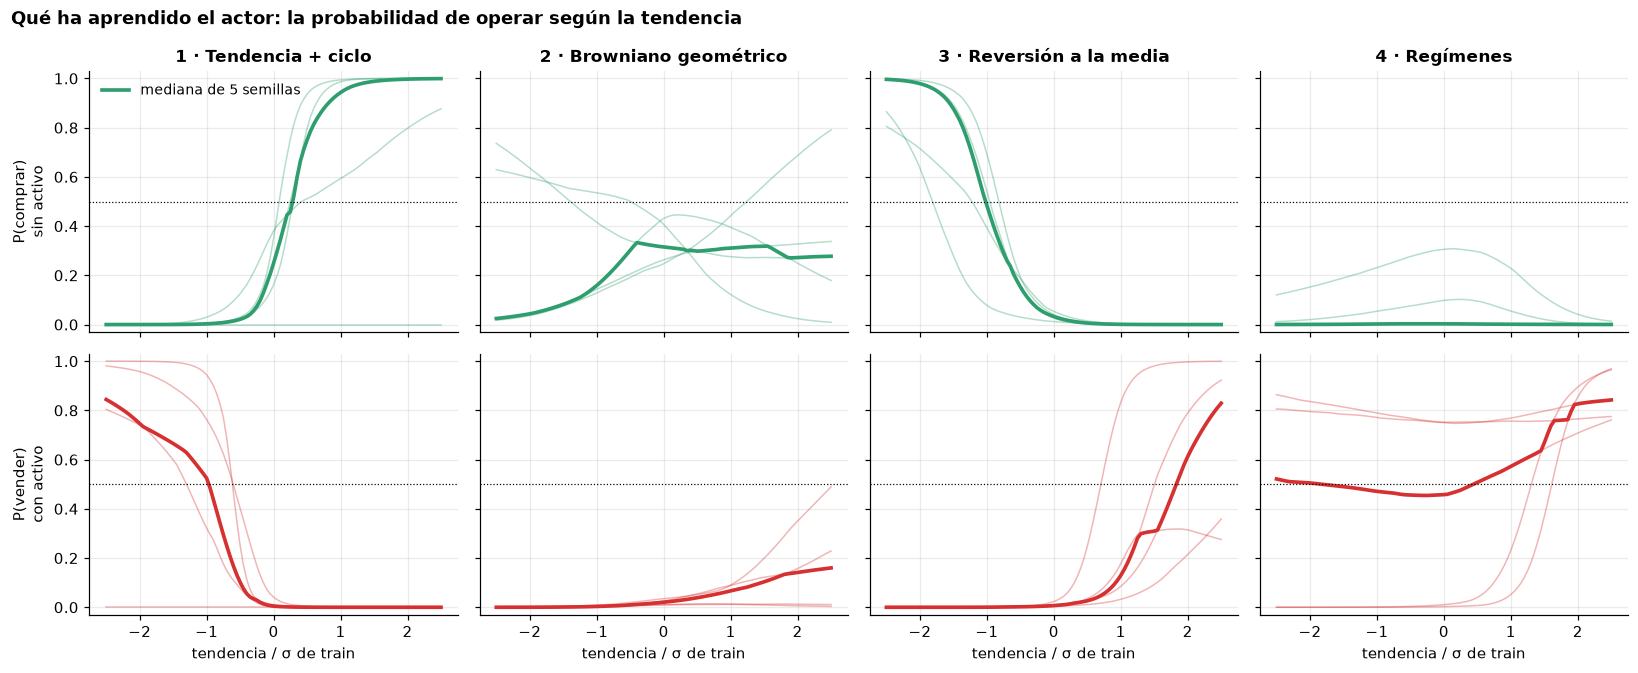

,P(comprar | sin activo),P(vender | con activo),reparto entre las dos acciones nulas
1 · Tendencia + ciclo,0.35,0.24,0.35
2 · Browniano geométrico,0.30,0.04,0.35
3 · Reversión a la media,0.27,0.17,0.28
4 · Regímenes,0.05,0.51,0.29


In [14]:
K = np.linspace(-2.5, 2.5, 101)
AGENTES = {m: [A3CAgent.load(f"a3c_{m}_s{s}") for s in range(N_SEEDS_FINAL)] for m in MERCADOS}


def p_rejilla(agente, posicion):
    tendencias = K * agente.scales[0]
    return np.array([agente.probs(np.array([t, posicion], dtype=np.float32)) for t in tendencias])


fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True, sharey=True)
filas = {}
for j, m in enumerate(MERCADOS):
    comprar, vender, nulas = [], [], []
    for agente in AGENTES[m]:
        p0, p1 = p_rejilla(agente, 0), p_rejilla(agente, 1)
        comprar.append(p0[:, BUY])
        vender.append(p1[:, SELL])
        nulas.append(np.r_[p0[:, SELL] / (p0[:, SELL] + p0[:, HOLD] + 1e-12), p1[:, BUY] / (p1[:, BUY] + p1[:, HOLD] + 1e-12)].mean())
    for ax, curvas_p, color in ((axes[0, j], comprar, POSITION_COLORS[1]), (axes[1, j], vender, POSITION_COLORS[0])):
        for c in curvas_p:
            ax.plot(K, c, color=color, alpha=0.35, lw=1)
        ax.plot(K, np.median(curvas_p, axis=0), color=color, lw=2.4, label="mediana de 5 semillas")
        ax.axhline(0.5, color="black", lw=0.8, ls=":")
        ax.set_ylim(-0.03, 1.03)
    axes[0, j].set_title(MARKET_LABELS[m])
    axes[1, j].set_xlabel("tendencia / σ de train")
    filas[MARKET_LABELS[m]] = {"P(comprar | sin activo)": np.mean(comprar), "P(vender | con activo)": np.mean(vender), "reparto entre las dos acciones nulas": np.mean(nulas)}
axes[0, 0].set_ylabel("P(comprar)\nsin activo")
axes[1, 0].set_ylabel("P(vender)\ncon activo")
axes[0, 0].legend()
fig.suptitle("Qué ha aprendido el actor: la probabilidad de operar según la tendencia", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "02_politica")
plt.show()
display(pd.DataFrame(filas).T.style.format("{:.2f}").set_caption("Medias sobre la rejilla de tendencias"))

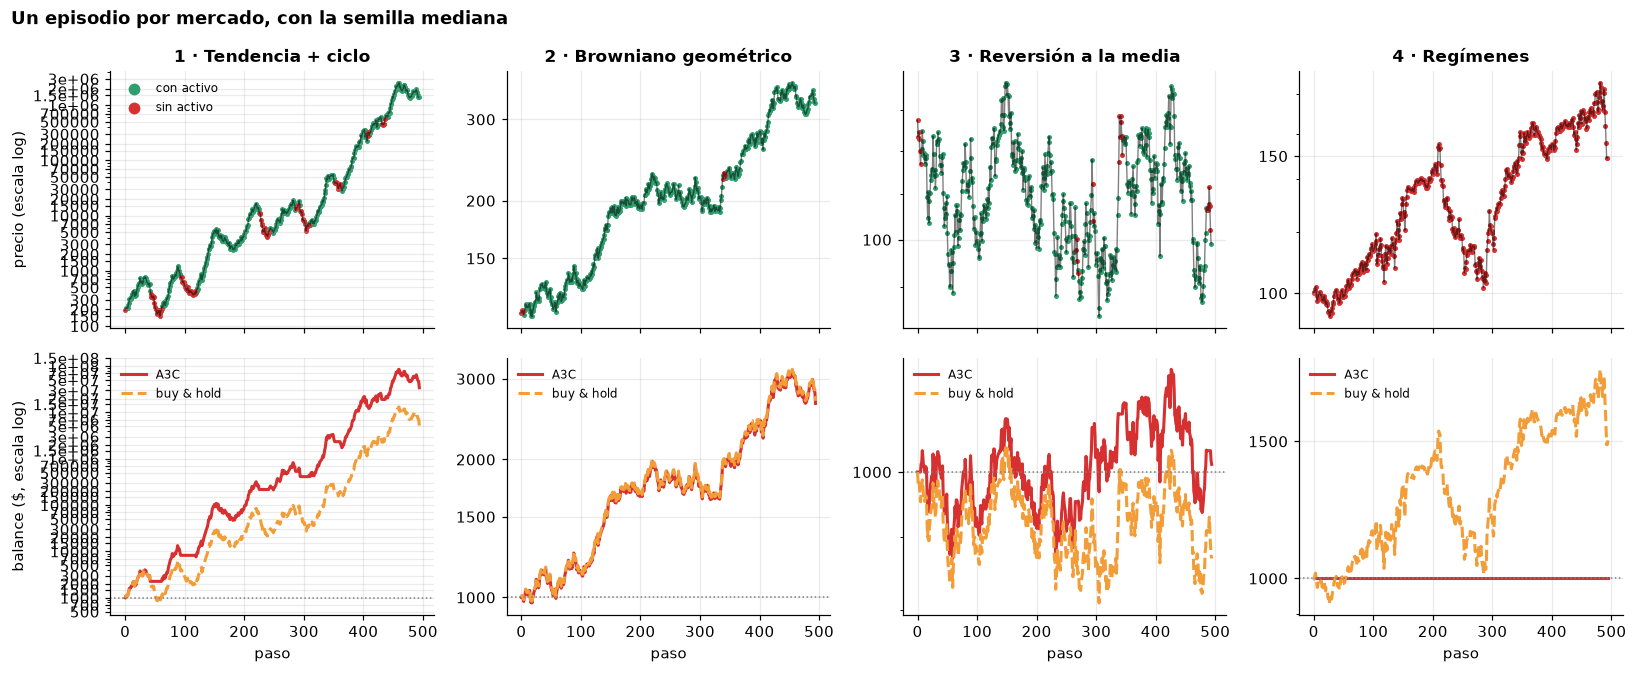

,tiempo con activo,operaciones en test
1 · Tendencia + ciclo,54%,34.9
2 · Browniano geométrico,91%,1.0
3 · Reversión a la media,75%,18.4
4 · Regímenes,0%,0.0


In [15]:
SERIE = VAL_SEED_OFFSET  # primera serie de validación: el test ya se ha usado
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharex=True)
filas = {}
for j, m in enumerate(MERCADOS):
    orden_semillas = np.argsort(final[final.mercado == m].retorno_mediana.to_numpy())
    agente = AGENTES[m][orden_semillas[len(orden_semillas) // 2]]  # la semilla mediana, no la mejor
    precios = make_prices(m, N_STEPS, SERIE)
    _, balance, _, posicion = run_episode(SimpleTradingEnv(precios), agente)
    validos = precios[5:-1]
    ax = axes[0, j]
    ax.plot(validos, color="black", lw=0.9, alpha=0.5)
    log_axis(ax)
    ax.scatter(np.flatnonzero(posicion == 1), validos[posicion == 1], s=5, color=POSITION_COLORS[1], label="con activo")
    ax.scatter(np.flatnonzero(posicion == 0), validos[posicion == 0], s=5, color=POSITION_COLORS[0], label="sin activo")
    ax.set_title(MARKET_LABELS[m])
    ax = axes[1, j]
    ax.plot(balance, color=AGENT_COLORS["a3c"], lw=2, label="A3C")
    ax.plot(run_episode(SimpleTradingEnv(precios), baseline_agents()["buy_hold"])[1], color=AGENT_COLORS["buy_hold"], lw=2, ls="--", label="buy & hold")
    ax.axhline(1000, color="gray", ls=":", lw=1)
    log_axis(ax)
    ax.set_xlabel("paso")
    ax.legend(fontsize=8)
    # Tiempo dentro en 20 series de validación, con las 5 semillas
    dentro = [run_episode(SimpleTradingEnv(make_prices(m, N_STEPS, VAL_SEED_OFFSET + i)), a)[3].mean() for a in AGENTES[m] for i in range(20)]
    filas[MARKET_LABELS[m]] = {"tiempo con activo": np.mean(dentro), "operaciones en test": resumen.set_index("mercado").n_trades[m]}
axes[0, 0].set_ylabel("precio (escala log)")
axes[0, 0].legend(fontsize=8, markerscale=3)
axes[1, 0].set_ylabel("balance ($, escala log)")
fig.suptitle("Un episodio por mercado, con la semilla mediana", x=0.01, ha="left", weight="bold")
fig.tight_layout()
savefig(fig, "02_episodios")
plt.show()
display(pd.DataFrame(filas).T.style.format({"tiempo con activo": "{:.0%}", "operaciones en test": "{:.1f}"}))

**Coincide con lo esperado en tres de los cuatro mercados:**

| Mercado | Esperado | Aprendido | ¿Coincide? |
|---|---|---|---|
| 1 | Seguir la tendencia | Compra con tendencia positiva y vende cuando cae por debajo de −1σ aproximadamente. Dentro el 54 % del tiempo, 34,9 operaciones | **Sí**, salvo la semilla que no opera |
| 2 | No operar | Salvo una semilla, entra y se queda: 1 operación y 91 % del tiempo dentro, con probabilidades sin forma común entre semillas | **No**, igual que DQN |
| 3 | Comprar tras caídas, vender tras subidas | Compra por debajo de −1σ y vende por encima de +1,7σ aproximadamente | **Sí**, pero vende tarde |
| 4 | No operar | No compra nunca: P(comprar) media de 0,05, 0 operaciones | **Sí** |

**Mercado 1:** la asimetría es razonable: compra enseguida y solo vende ante una caída clara. Es la misma lógica que `regla_tendencia`, pero menos nítida entre semillas.

**Mercado 2:** con la deriva de −0,0001 por paso en logaritmo y +0,0001 en retorno simple que vimos en DQN, la recompensa favorece estar dentro, aunque el balance no. Una vez dentro, casi no vende, así que se comporta como buy & hold (la figura de abajo lo muestra: las dos curvas casi coinciden).

**Mercado 3:** el umbral de compra es parecido entre semillas, y el de venta varía mucho. La mediana solo pasa de 0,5 hacia +1,7σ, y una semilla apenas vende. Por eso está dentro el 75 % del tiempo, y eso puede explicar parte de la distancia con la regla.

**Mercado 4:** las curvas de P(vender) del panel inferior no significan nada. El agente nunca tiene el activo, así que esos estados no se visitan y su política no se ha entrenado. Es una advertencia general: la política solo es fiable en lo que el agente visita.

## 6. Convergencia (ejercicio 4)

Las dos curvas de D-0.3, con el retorno sobre el balance para que sean comparables:

- **Con exploración:** el retorno de cada episodio de entrenamiento, muestreando de la política (mediana móvil de 25 episodios).
- **Sin exploración:** la acción más probable cada 24 episodios totales, en 20 series de validación fijas.

En A3C los episodios transcurren en paralelo, así que el eje son episodios totales, y el tiempo se compara aparte. Parte de la distancia entre ambas curvas es ruido, porque usan series distintas y la segunda solo tiene 20.

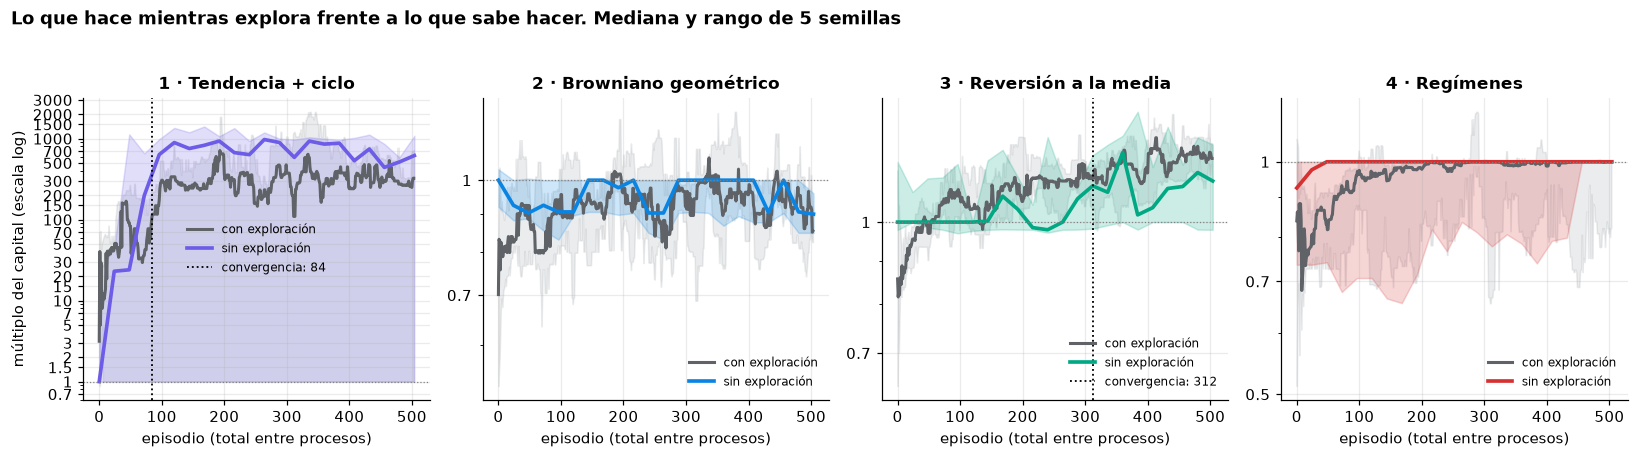

,semillas que convergen,episodios,pasos de entorno,segundos,criterio del Taller 1 (episodios),entrenamiento total (s)
1 · Tendencia + ciclo,4 de 5,84,41496,2,122,10
2 · Browniano geométrico,0 de 5,ninguna,ninguna,ninguna,108,10
3 · Reversión a la media,3 de 5,312,154128,6,306,10
4 · Regímenes,0 de 5,ninguna,ninguna,ninguna,122,10


estado_convergencia,converge,no opera,no mejora
mercado,,,
1 · Tendencia + ciclo,4,1,0
2 · Browniano geométrico,0,0,5
3 · Reversión a la media,3,0,2
4 · Regímenes,0,5,0


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharex=False)
for ax, m in zip(axes, MERCADOS):
    curvas_m = CURVAS[m]
    con = np.array([pd.Series(1 + c["retorno"]).rolling(25, min_periods=1).median() for c in curvas_m])
    sin = 1 + np.array([c["val_retorno"] for c in curvas_m])
    x = np.arange(con.shape[1])
    ax.fill_between(x, con.min(axis=0), con.max(axis=0), color="#9AA0A6", alpha=0.2)
    ax.plot(x, np.median(con, axis=0), color="#5F6368", lw=2, label="con exploración")
    e = curvas_m[0]["val_episodios"]
    ax.fill_between(e, sin.min(axis=0), sin.max(axis=0), color=MARKET_COLORS[m], alpha=0.2)
    ax.plot(e, np.median(sin, axis=0), color=MARKET_COLORS[m], lw=2.4, label="sin exploración")
    conv = resumen.set_index("mercado").episodios_convergencia[m]
    if np.isfinite(conv):
        ax.axvline(conv, color="black", ls=":", lw=1.2, label=f"convergencia: {conv:.0f}")
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    log_axis(ax)
    ax.set_title(MARKET_LABELS[m])
    ax.set_xlabel("episodio (total entre procesos)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("múltiplo del capital (escala log)")
fig.suptitle("Lo que hace mientras explora frente a lo que sabe hacer. Mediana y rango de 5 semillas", x=0.01, ha="left", weight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "02_dos_curvas")
plt.show()

tabla = final.groupby("mercado", sort=False)[["episodios_convergencia", "pasos_convergencia", "tiempo_convergencia_s", "episodios_convergencia_taller1", "tiempo_s"]].median().loc[MERCADOS]
tabla.index = [MARKET_LABELS[m] for m in MERCADOS]
tabla.columns = ["episodios", "pasos de entorno", "segundos", "criterio del Taller 1 (episodios)", "entrenamiento total (s)"]
tabla.insert(0, "semillas que convergen", [f"{(final[final.mercado == m].estado_convergencia == 'converge').sum()} de {N_SEEDS_FINAL}" for m in MERCADOS])
display(tabla.style.format("{:.0f}", na_rep="ninguna", subset=tabla.columns[1:]))
display(final.groupby("mercado", sort=False).estado_convergencia.value_counts().unstack(fill_value=0).loc[MERCADOS].rename(index=MARKET_LABELS))

**Tiempo frente a DQN.** Los segundos de `results/01_dqn.csv` se midieron en otro equipo, así que no se pueden comparar con los de este notebook. Aquí se entrena DQN en **este mismo equipo**, una semilla por mercado y con su configuración base, solo para medir el tiempo; el resultado de DQN no cambia.

In [17]:
BASE_DQN = {"split": "val", "lr": 1e-3, "gamma": 0.9, "epsilon_decay": 0.995, "n_episodes": 500, "use_target": True, "normalize_obs": True, "normalize_reward": True}
tiempos_dqn, _ = run_grid([{**BASE_DQN, "mercado": m, "seed": 0} for m in MERCADOS], dqn.entrena_y_evalua, "02_grid_tiempo_dqn", n_jobs=1)
PASOS = N_STEPS - 6
filas = {}
for m in MERCADOS:
    a = final[final.mercado == m]
    t_dqn = tiempos_dqn[tiempos_dqn.mercado == m].tiempo_s.iloc[0]
    filas[MARKET_LABELS[m]] = {"DQN (s, 500 episodios)": t_dqn, "A3C (s)": a.tiempo_s.median(), "episodios A3C": ACTUAL[m]["n_episodes"],
                               "pasos/s DQN": 500 * PASOS / t_dqn, "pasos/s A3C": ACTUAL[m]["n_episodes"] * PASOS / a.tiempo_s.median()}
display(pd.DataFrame(filas).T.style.format("{:.0f}").set_caption(f"Entrenamiento en este equipo ({os.cpu_count()} núcleos lógicos, 3 procesos de A3C)"))

Entrenando 4 configuraciones en 1 procesos (0 en caché)...


,"DQN (s, 500 episodios)",A3C (s),episodios A3C,pasos/s DQN,pasos/s A3C
1 · Tendencia + ciclo,33,10,500,7508,25102
2 · Browniano geométrico,33,10,500,7498,24992
3 · Reversión a la media,33,10,500,7461,25014
4 · Regímenes,33,10,500,7471,25244


**Convergencia, en la curva sin exploración (D-0.3):**

| Mercado | Semillas que convergen | Episodios | Pasos de entorno | Segundos | Lectura |
|---|---|---|---|---|---|
| 1 | 4 de 5 | 84 | 41 496 | 2 | Aprende muy pronto; la otra semilla no opera |
| 2 | 0 de 5 | — | — | — | Las 5 no mejoran: no hay nada que aprender |
| 3 | 3 de 5 | 312 | 154 128 | 6 | Lento, y 2 semillas no mejoran |
| 4 | 0 de 5 | — | — | — | Las 5 acaban sin operar, que es lo correcto |

**Frente a DQN** (5 de 5 en 25 episodios en el mercado 1, y 5 de 5 en 125 en el 3), A3C necesita más episodios y converge menos veces.

**En tiempo sí es más rápido.** A3C tarda 10 s frente a 33 s de DQN en este equipo, 25 000 pasos/s frente a 7 500: 3,3 veces más con 3 procesos. Sin *replay* ni red objetivo, cada paso cuesta menos y los procesos escalan. Aun así, al ritmo de DQN sus puntos de convergencia caerían en torno a 2 s y 8 s, frente a 2 s y 6 s: **A3C entrena más rápido, pero no llega antes a una política buena de forma clara.** Ninguno de los dos tiempos cuenta evaluaciones, y el de A3C tampoco el arranque de los procesos. DQN se midió con una semilla por mercado.

**La figura lleva a la misma cautela que en DQN.** La política sigue cambiando hasta el final: en el mercado 1, la mediana oscila entre unos x400 y x1 000; en el 3, sube y baja después del punto de convergencia, así que este criterio hay que leerlo con cuidado. En el mercado 3, la curva con exploración va por encima de la curva sin exploración casi todo el entrenamiento: encaja con que muestrear supere a la acción más probable en ese mercado (§4), aunque parte de la distancia puede ser ruido, porque usan series distintas.

Para comparar con el Taller 1: el criterio antiguo daría entre 108 y 306 episodios, pero mide sobre la recompensa con exploración y no es comparable.

## 7. ¿Se puede mejorar?

El §6 de DQN y el de aquí señalan lo mismo: el modelo final es una foto de un momento concreto. En DQN, la mejora más prometedora fue quedarse con **el mejor punto en validación** (D-2.5). Se prueba aquí con el mismo procedimiento y por la misma razón.

**El test ya se ha visto** (D-2.4), así que el resultado del §4 se queda como resultado oficial. Elegir el punto en validación y comparar en validación daría una cifra inflada, de modo que se mide directamente en las **400 series nuevas** (semillas desde 400 000), con 5 semillas, frente a los modelos del §4. Es solo informativo.

In [18]:
SEMILLAS = list(range(N_SEEDS_FINAL))
run_grid([{**ACTUAL[m], "best_checkpoint": True, "mercado": m, "seed": s, "guardar": f"a3c_mejor_punto_{m}_s{s}"} for m in MERCADOS for s in SEMILLAS],
         entrena_y_evalua, "02_grid_mejor_punto", n_jobs=N_JOBS)
evaluar = lambda nombre, prefijo: run_grid([{"modelo": f"{prefijo}_{m}_s{s}", "mercado": m, "seed": s, "split": "nuevas"} for m in MERCADOS for s in SEMILLAS], evalua_modelo, nombre, n_jobs=1)
base_n, curvas_base_n = evaluar("02_grid_nuevas_base", "a3c")
punto_n, curvas_punto_n = evaluar("02_grid_nuevas_mejor_punto", "a3c_mejor_punto")
umbrales_ref = pd.read_csv(RESULTS_DIR / "00_grid_referencias.csv").set_index(["agente", "mercado"]).umbral
refs_n, curvas_refs = run_grid([{"agente": a, "mercado": m, "umbral": float(umbrales_ref[a, m]) if a in RULES else 0.0, "split": "nuevas"} for m, a in REFERENCIA.items()],
                               evaluate_reference, "02_grid_nuevas_referencias", n_jobs=1)


def lista(df, curvas_df, m):
    return [curvas_df[i] for i in df[df.mercado == m].sort_values("seed").id]


filas = {}
for m in MERCADOS:
    b, p = base_n[base_n.mercado == m].retorno_mediana, punto_n[punto_n.mercado == m].retorno_mediana
    ventaja, ganan = ventaja_emparejada(lista(punto_n, curvas_punto_n, m), lista(base_n, curvas_base_n, m))
    filas[MARKET_LABELS[m]] = {"base": formato(b.median()), "rango base": f"{formato(b.min())} a {formato(b.max())}", "mejor punto": formato(p.median()), "rango mejor punto": f"{formato(p.min())} a {formato(p.max())}",
                               "referencia": formato(refs_n[refs_n.mercado == m].retorno_mediana.iloc[0]), "ventaja (log)": f"{ventaja:+.3f}", "margen": f"{margen_log(m):.2f}", "semillas que mejoran": f"{ganan} de 5"}
display(pd.DataFrame(filas).T.style.set_caption("Mejor punto frente a la base, en las 400 series nuevas"))

Entrenando 20 configuraciones en 1 procesos (0 en caché)...
Entrenando 20 configuraciones en 1 procesos (0 en caché)...
Entrenando 20 configuraciones en 1 procesos (0 en caché)...
Entrenando 4 configuraciones en 1 procesos (0 en caché)...


,base,rango base,mejor punto,rango mejor punto,referencia,ventaja (log),margen,semillas que mejoran
1 · Tendencia + ciclo,x388.2,+0.0% a x528.1,x480.3,x17.8 a x511.8,x530.2,+0.337,0.22,3 de 5
2 · Browniano geométrico,-6.4%,-8.2% a +0.0%,-6.9%,-7.6% a +0.0%,+0.0%,+0.000,0.10,1 de 5
3 · Reversión a la media,+15.8%,+3.1% a +22.6%,+30.1%,+6.0% a +33.1%,+32.7%,+0.072,0.02,4 de 5
4 · Regímenes,+0.0%,+0.0% a +0.0%,+0.0%,-19.5% a +0.0%,+0.0%,+0.000,0.10,0 de 5


**Sí sirve, y más que en DQN.** En las 400 series nuevas supera el margen de ruido en los dos mercados con señal:

- **Mercado 1:** de x388,2 a x480,3 (ventaja +0,337, margen 0,22), y mejoran 3 de 5 semillas. La peor semilla pasa de +0,0 % a x17,8.
- **Mercado 3:** de +15,8 % a +30,1 % (ventaja +0,072, margen 0,02), y mejoran 4 de 5 semillas. Se queda cerca de la regla (+32,7 %), aunque la peor semilla sigue en +6,0 %.
- **Mercados 2 y 4:** no mejora. En el browniano queda en −6,9 % frente a −6,4 %, y en regímenes puede salir perjudicado: la peor semilla baja a −19,5 %, probablemente porque el punto se elige con solo 20 series.

En las mismas series, A3C con mejor punto da x480,3 y +30,1 %, frente a x356,7 y +29,6 % de DQN con mejor punto. Las bases son x388,2 y +15,8 % frente a x287,4 y +24,5 %. **A3C gana más con esto que DQN,** lo que sugiere que en el mercado 3 su problema es sobre todo acabar en un mal momento, no que no sepa operar.

**El resultado oficial sigue siendo el del §4.** Esta medida es única, informativa y posterior al test; en ningún mercado alcanza a la referencia (x530,2 y +32,7 %).

## 8. Conclusiones

**Qué funciona:**

- A3C aprende la estrategia esperada en tendencia, reversión y regímenes, sin discretizar y sin ε.
- Procesa unas 3,3 veces más pasos de entorno por segundo que DQN, con 3 procesos.
- Bate con claridad a buy & hold y al aleatorio en los mercados con señal.
- Normalizar la observación es imprescindible (D-1.1).

**Qué no funciona:**

- **No supera a las reglas simples ni a la tabla Q del Taller 1:** x374,9 frente a x630,4 y +13,8 % frente a +29,2 %. Pierde en el 68 % y el 75 % de las series.
- **Frente a DQN,** queda por debajo en reversión (+13,8 % frente a +20,5 %) y no se distingue en el resto. Tampoco converge antes en episodios, ni de forma clara en tiempo.
- **Es inestable.** En el mercado 1, una de cinco semillas no opera, y en el 3 van de +2,9 % a +18,8 %. La política sigue cambiando al final del entrenamiento.
- **En el browniano no se queda fuera:** entra y se queda, como DQN, porque la recompensa no coincide con el balance.

**Lo que no se puede concluir:**

- Que estos hiperparámetros sean óptimos: se ajustaron uno a uno con 3 semillas, y el +25,9 % de validación del mercado 3 no se sostuvo en test.
- Que A3C sea mejor o peor que DQN en general: este problema tiene un estado de dos variables y no permite extrapolar.
- Que los segundos valgan para otro equipo, y A3C no es reproducible bit a bit, porque los procesos compiten por los pesos (D-2.1). Por eso se informa de la dispersión.

**Qué pasó al intentar mejorarlo (§7):** quedarse con el mejor punto en validación supera el margen en los mercados 1 y 3 en 400 series nuevas (x480,3 y +30,1 %). Es la misma conclusión que en DQN y con más fuerza: **lo que más limita a A3C aquí parece ser la estabilidad, no la capacidad**. La cifra no sustituye a la del §4 y sigue por debajo de las reglas.

**Si hubiera que seguir:** empezar por estabilizar. Elegir el punto con más de 20 series de validación y reducir α al final del entrenamiento son los dos pasos naturales.